In [1]:
# Import Path to manage file locations
from pathlib import Path

# Import pandas to create the metrics comparison table
import pandas as pd

# Import matplotlib for plotting graphs
import matplotlib.pyplot as plt

# Import seaborn for attractive statistical visualizations
import seaborn as sns

# Import joblib to load trained models
import joblib

# Import the required evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

# Apply a consistent visual style to plots
sns.set_theme(style="whitegrid")

In [3]:
# Define the path of the processed test dataset
TEST_PATH = Path("../data/processed/test_data.csv")

# Load the test dataset
test_data = pd.read_csv(TEST_PATH)

# Separate test features from the target column
X_test = test_data.drop(columns=["price_range"])

# Store the actual target values
y_test = test_data["price_range"]

# Display the test data dimensions
print("Test feature shape:", X_test.shape)
print("Test target shape:", y_test.shape)

Test feature shape: (400, 20)
Test target shape: (400,)


In [5]:
# Define the folder containing the saved trained models
MODEL_DIR = Path("../model")

# Define the filenames of all five trained models
model_filenames = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "Support Vector Machine": "svm.joblib"
}

# Create an empty dictionary to store the loaded models
models = {}

# Load each trained model from disk
for model_name, filename in model_filenames.items():
    # Build the complete path to the model file
    model_path = MODEL_DIR / filename

    # Load the trained pipeline
    models[model_name] = joblib.load(model_path)

    # Confirm that the model was loaded
    print(f"{model_name} loaded successfully.")

Logistic Regression loaded successfully.
Decision Tree loaded successfully.
KNN loaded successfully.
Naive Bayes loaded successfully.
Support Vector Machine loaded successfully.


In [7]:
# Create an empty list to store the evaluation results
evaluation_results = []

# Evaluate each trained model
for model_name, model_pipeline in models.items():
    # Generate class predictions for the test dataset
    y_pred = model_pipeline.predict(X_test)

    # Generate class probabilities for multiclass AUC calculation
    y_probability = model_pipeline.predict_proba(X_test)

    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)

    # Calculate multiclass One-vs-Rest weighted AUC
    auc_score = roc_auc_score(
        y_test,
        y_probability,
        multi_class="ovr",
        average="weighted"
    )

    # Calculate weighted precision
    precision = precision_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    # Calculate weighted recall
    recall = recall_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    # Calculate weighted F1 score
    f1 = f1_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    # Calculate the multiclass Matthews Correlation Coefficient
    mcc = matthews_corrcoef(y_test, y_pred)

    # Store all metrics for the current model
    evaluation_results.append({
        "ML Model Name": model_name,
        "Accuracy": accuracy,
        "AUC": auc_score,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "MCC": mcc
    })

# Convert the results list into a DataFrame
metrics_df = pd.DataFrame(evaluation_results)

# Display the metrics rounded to four decimal places
display(metrics_df.round(4))

,ML Model Name,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.965,0.9987,0.9650,0.965,0.9650,0.9534
1,Decision Tree,0.830,0.8867,0.8319,0.830,0.8302,0.7738
2,KNN,0.500,0.7697,0.5211,0.500,0.5054,0.3350
3,Naive Bayes,0.810,0.9506,0.8113,0.810,0.8105,0.7468
4,Support Vector Machine,0.895,0.9834,0.8969,0.895,0.8956,0.8602


In [9]:
# Create a copy of the metrics table for presentation
comparison_table = metrics_df.copy()

# Round all numerical metrics to four decimal places
comparison_table.iloc[:, 1:] = comparison_table.iloc[:, 1:].round(4)

# Display the final comparison table
display(comparison_table)

,ML Model Name,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.965,0.9987,0.9650,0.965,0.9650,0.9534
1,Decision Tree,0.830,0.8867,0.8319,0.830,0.8302,0.7738
2,KNN,0.500,0.7697,0.5211,0.500,0.5054,0.3350
3,Naive Bayes,0.810,0.9506,0.8113,0.810,0.8105,0.7468
4,Support Vector Machine,0.895,0.9834,0.8969,0.895,0.8956,0.8602


In [11]:
# Define the folder for processed output files
PROCESSED_DIR = Path("../data/processed")

# Save the complete metrics table as a CSV file
metrics_df.to_csv(
    PROCESSED_DIR / "model_metrics.csv",
    index=False
)

# Confirm that the metrics file was saved
print("Metrics saved to:", PROCESSED_DIR / "model_metrics.csv")

Metrics saved to: ../data/processed/model_metrics.csv


In [13]:
# Generate a detailed classification report for every model
for model_name, model_pipeline in models.items():
    # Generate predictions for the current model
    y_pred = model_pipeline.predict(X_test)

    # Print the model name
    print("=" * 70)
    print(model_name)

    # Display precision, recall, F1, and support for every class
    print(
        classification_report(
            y_test,
            y_pred,
            zero_division=0
        )
    )

Logistic Regression
              precision    recall  f1-score   support

           0       0.99      0.98      0.98       100
           1       0.96      0.96      0.96       100
           2       0.95      0.94      0.94       100
           3       0.96      0.98      0.97       100

    accuracy                           0.96       400
   macro avg       0.97      0.96      0.96       400
weighted avg       0.97      0.96      0.96       400

Decision Tree
              precision    recall  f1-score   support

           0       0.88      0.92      0.90       100
           1       0.78      0.74      0.76       100
           2       0.75      0.80      0.77       100
           3       0.92      0.86      0.89       100

    accuracy                           0.83       400
   macro avg       0.83      0.83      0.83       400
weighted avg       0.83      0.83      0.83       400

KNN
              precision    recall  f1-score   support

           0       0.65      0.70    

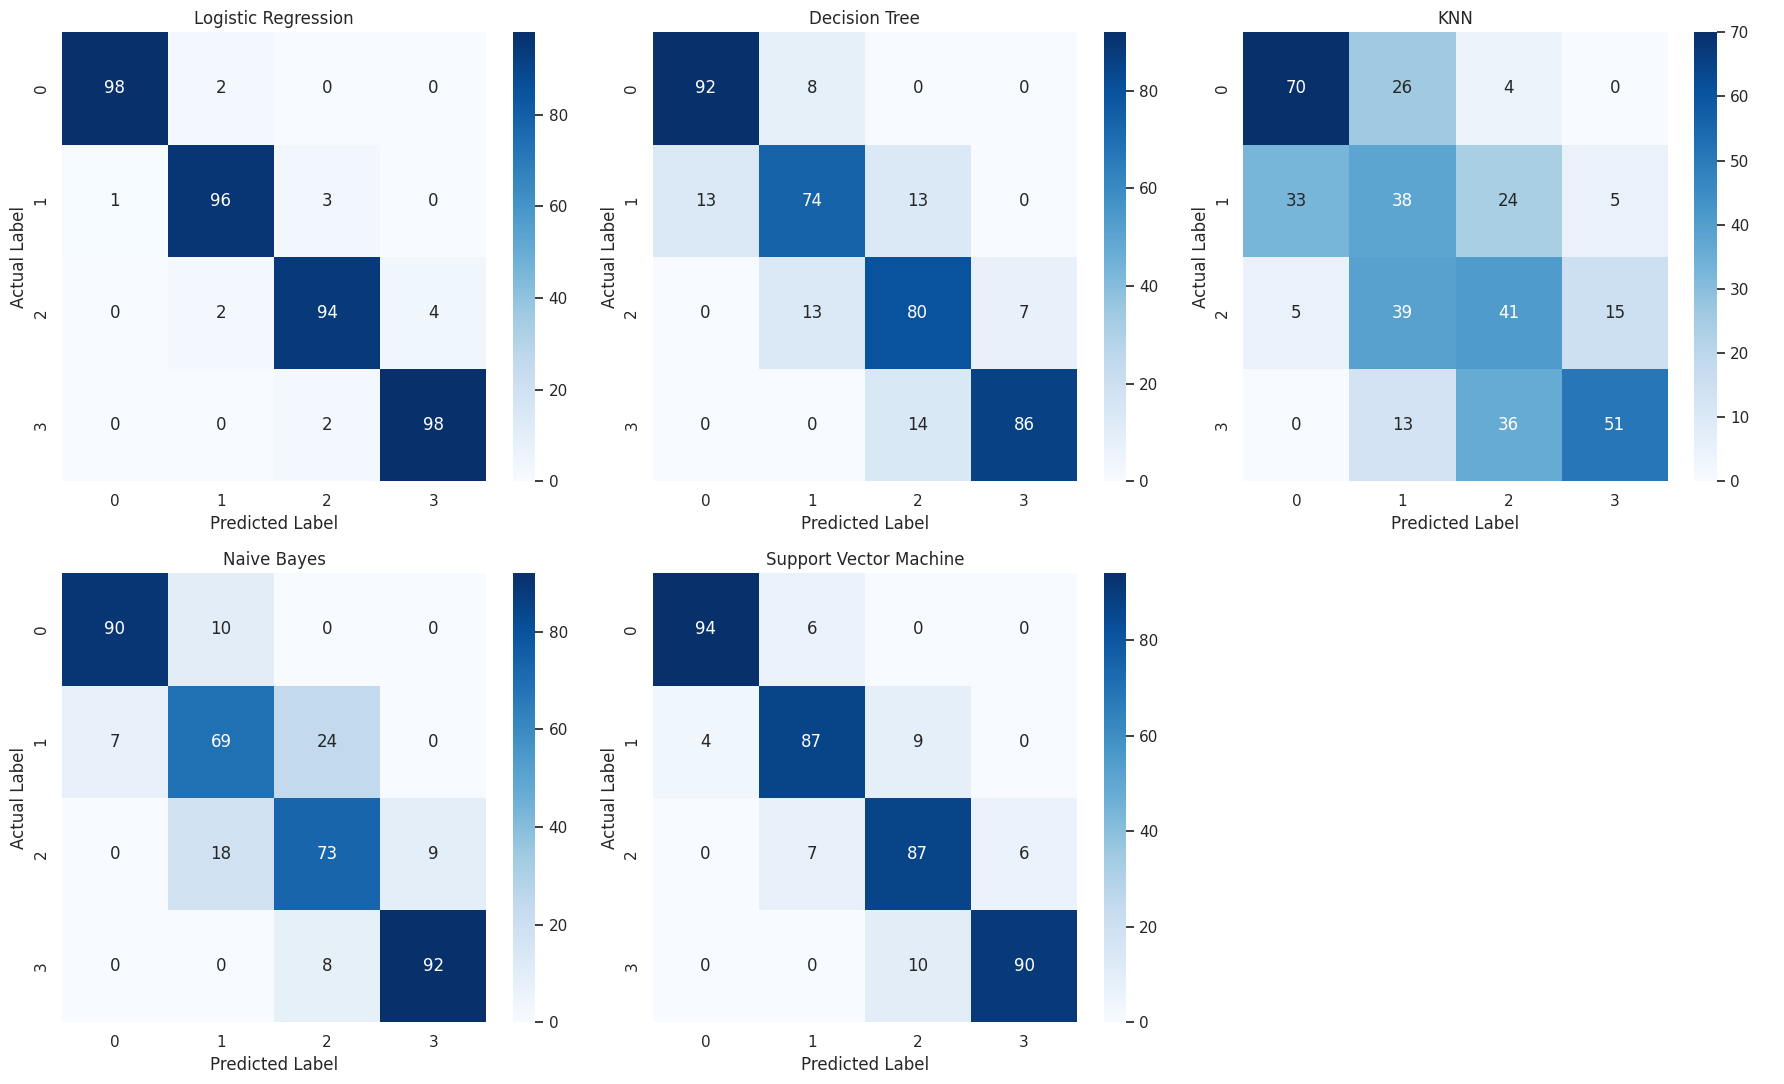

In [15]:
# Create a figure containing one confusion matrix for each model
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(18, 11)
)

# Flatten the axes array for easier iteration
axes = axes.flatten()

# Plot the confusion matrix for each model
for index, (model_name, model_pipeline) in enumerate(models.items()):
    # Generate predictions for the current model
    y_pred = model_pipeline.predict(X_test)

    # Calculate the confusion matrix
    matrix = confusion_matrix(y_test, y_pred)

    # Plot the confusion matrix
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=axes[index]
    )

    # Add a title to the subplot
    axes[index].set_title(model_name)

    # Label the horizontal axis
    axes[index].set_xlabel("Predicted Label")

    # Label the vertical axis
    axes[index].set_ylabel("Actual Label")

# Hide the unused sixth subplot
axes[-1].axis("off")

# Adjust spacing between plots
plt.tight_layout()

# Display all confusion matrices
plt.show()

In [17]:
# Find the model with the highest weighted F1 score
winner_row = metrics_df.loc[metrics_df["F1 Score"].idxmax()]

# Display the best-performing model
print("Best model based on weighted F1 Score:")
print(winner_row["ML Model Name"])

# Display its metric values
display(winner_row.to_frame().T.round(4))

Best model based on weighted F1 Score:
Logistic Regression


,ML Model Name,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.965,0.998667,0.965045,0.965,0.964986,0.953357
